<a href="https://colab.research.google.com/github/Hunter-Rudra/streamlit-real-estate-analytics/blob/main/streamlit-real-estate-analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

In [3]:
dataset = files.upload()

Saving housing.csv to housing.csv


# Data Info

In [4]:
data = pd.read_csv("housing.csv")

In [5]:
data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


Dropping NULL datasets

In [7]:
data.dropna(inplace=True)

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20433 non-null  float64
 1   latitude            20433 non-null  float64
 2   housing_median_age  20433 non-null  float64
 3   total_rooms         20433 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20433 non-null  float64
 6   households          20433 non-null  float64
 7   median_income       20433 non-null  float64
 8   median_house_value  20433 non-null  float64
 9   ocean_proximity     20433 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.7+ MB


Splitting Training dataset and Test dataset

In [9]:
from sklearn.model_selection import train_test_split

X = data.drop(['median_house_value'], axis=1)
Y = data['median_house_value']

In [10]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2)

In [11]:
train_data = X_train.join(Y_train)

In [12]:
train_data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_house_value
3802,-118.43,34.20,20.0,4090.0,1271.0,2824.0,1053.0,2.7730,<1H OCEAN,140500.0
10832,-117.93,33.65,34.0,2141.0,425.0,1559.0,429.0,4.2036,<1H OCEAN,220100.0
20166,-119.29,34.44,34.0,4314.0,878.0,2361.0,831.0,3.2279,NEAR OCEAN,243100.0
2042,-119.69,36.74,23.0,2097.0,385.0,911.0,405.0,3.5128,INLAND,121600.0
9474,-123.32,39.42,22.0,2085.0,432.0,1133.0,402.0,2.3906,<1H OCEAN,92600.0
...,...,...,...,...,...,...,...,...,...,...
6033,-117.73,34.08,28.0,5173.0,1069.0,3502.0,954.0,3.8438,INLAND,130800.0
5768,-118.30,34.16,40.0,1875.0,460.0,869.0,438.0,3.2321,<1H OCEAN,243600.0
6886,-118.10,34.06,31.0,2852.0,740.0,3100.0,725.0,2.9524,<1H OCEAN,178800.0
18912,-122.24,38.15,10.0,6817.0,1188.0,4163.0,1135.0,4.4529,NEAR BAY,144100.0


Features extraction of data

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

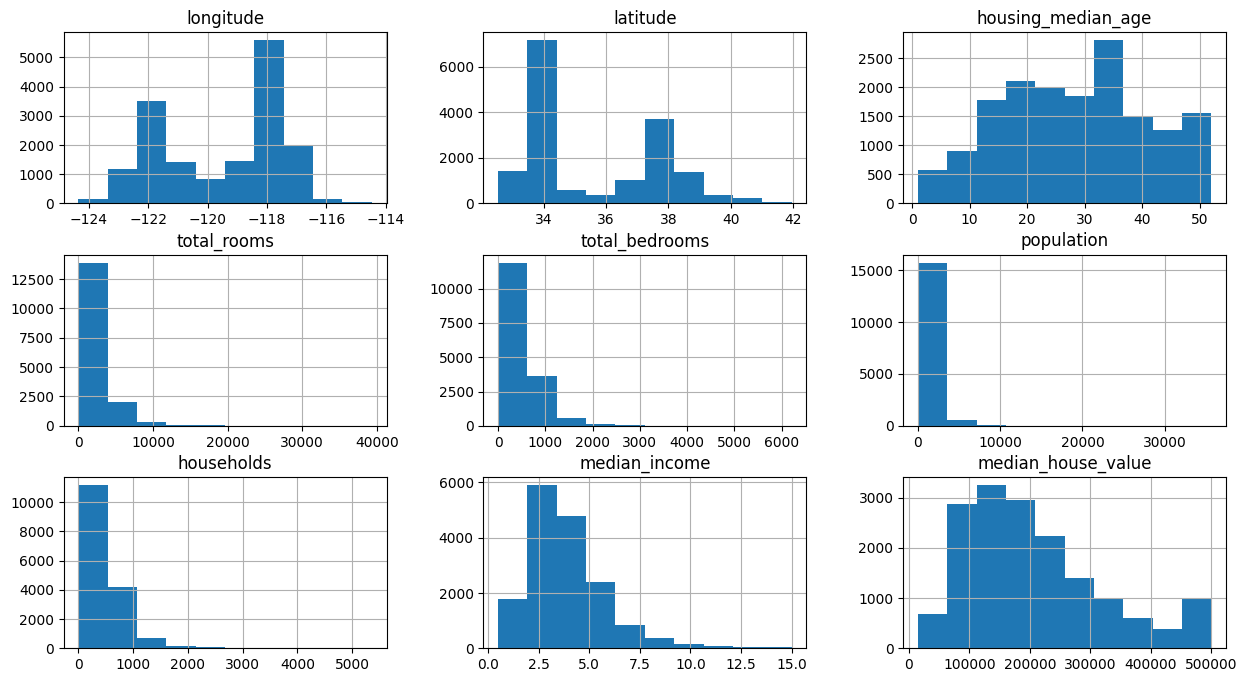

In [13]:
train_data.hist(figsize=(15, 8))

Correlation Extraction of data

In [14]:
train_data.corr(numeric_only=True)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924871,-0.108899,0.049666,0.072280,0.108455,0.060209,-0.017785,-0.047621
latitude,-0.924871,1.000000,0.012232,-0.042019,-0.070680,-0.116807,-0.074982,-0.077725,-0.141939
housing_median_age,-0.108899,0.012232,1.000000,-0.361311,-0.319323,-0.297779,-0.302081,-0.124694,0.103813
total_rooms,0.049666,-0.042019,-0.361311,1.000000,0.929316,0.860342,0.920041,0.207701,0.141182
total_bedrooms,0.072280,-0.070680,-0.319323,0.929316,1.000000,0.879809,0.981334,-0.000145,0.057838
population,0.108455,-0.116807,-0.297779,0.860342,0.879809,1.000000,0.907557,0.011426,-0.018777
households,0.060209,-0.074982,-0.302081,0.920041,0.981334,0.907557,1.000000,0.021208,0.073186
median_income,-0.017785,-0.077725,-0.124694,0.207701,-0.000145,0.011426,0.021208,1.000000,0.687889
median_house_value,-0.047621,-0.141939,0.103813,0.141182,0.057838,-0.018777,0.073186,0.687889,1.000000


<Axes: >

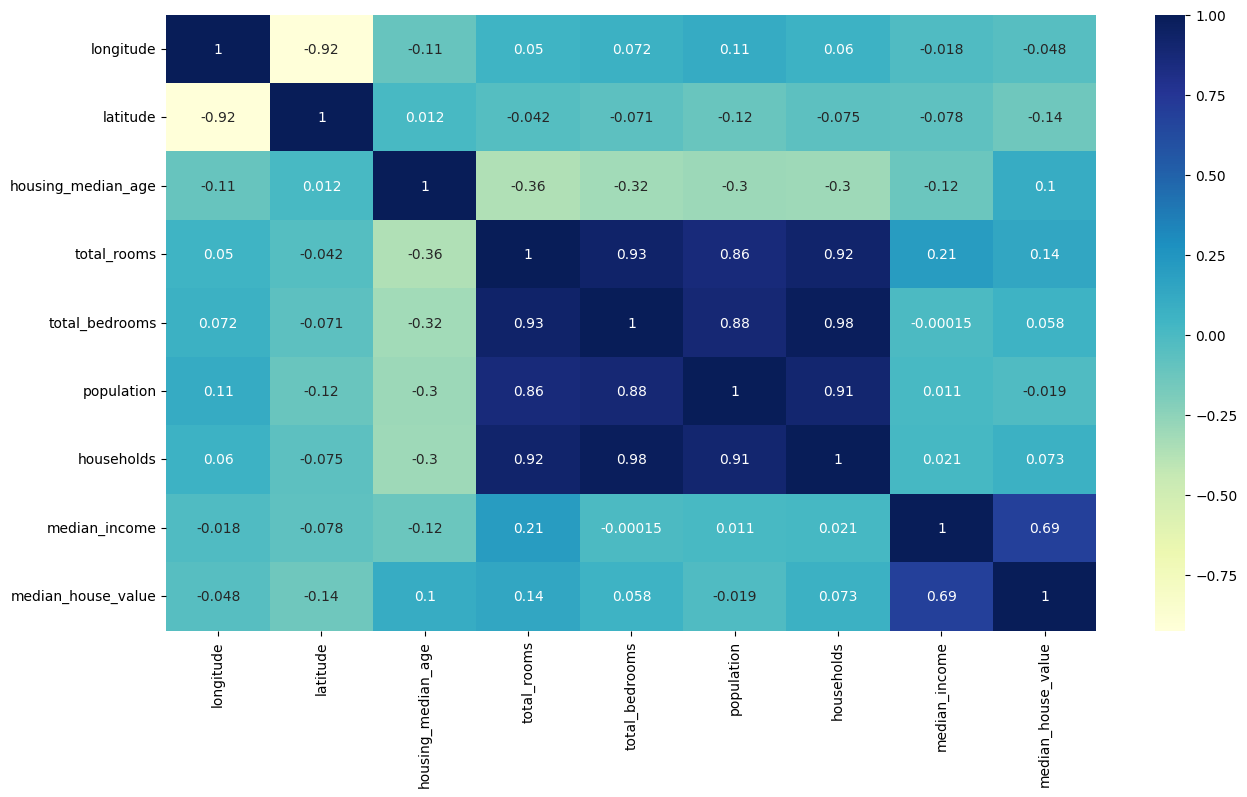

In [15]:
plt.figure(figsize = (15, 8))
sns.heatmap(train_data.corr(numeric_only=True), annot=True, cmap="YlGnBu")

Using Logrethmic function to know the Data Type

In [16]:
train_data['total_rooms'] = np.log(train_data['total_rooms'] + 1)
train_data['total_bedrooms'] = np.log(train_data['total_bedrooms'] + 1)
train_data['population'] = np.log(train_data['population'] + 1)
train_data['households'] = np.log(train_data['households'] + 1)

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

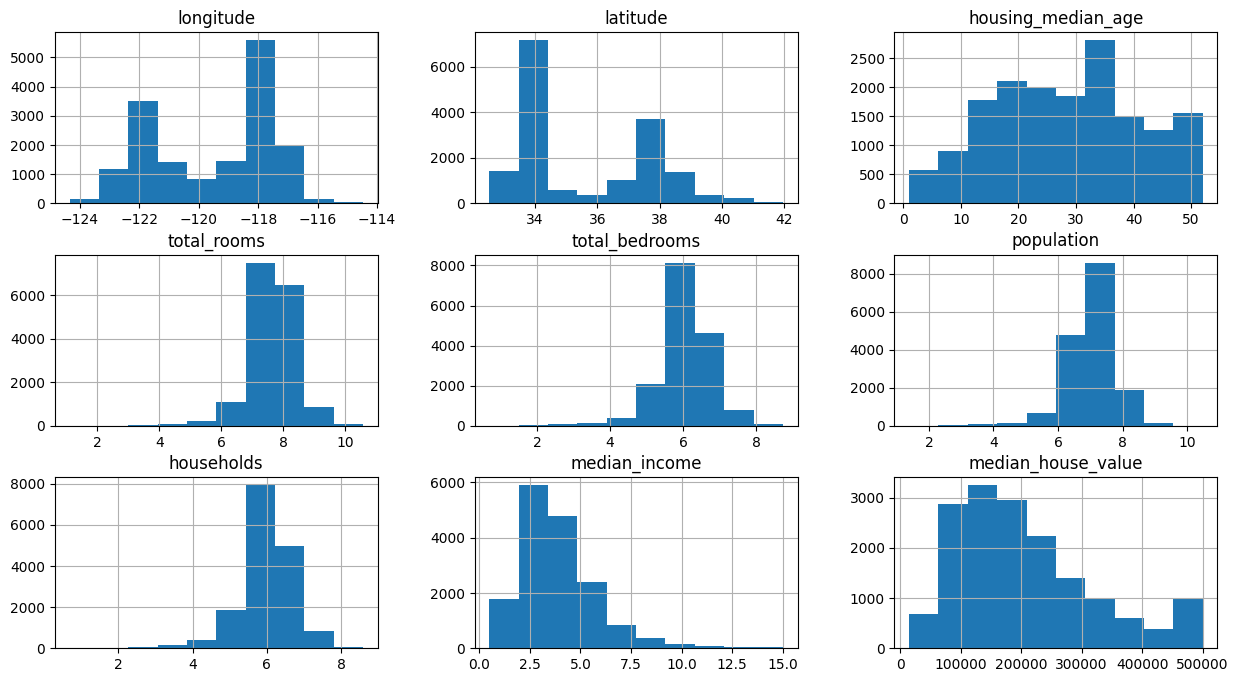

In [17]:
train_data.hist(figsize=(15, 8))

OH Encoding for Ocean Category

In [18]:
train_data.ocean_proximity.value_counts()

,count
ocean_proximity,
<1H OCEAN,7285
INLAND,5165
NEAR OCEAN,2096
NEAR BAY,1797
ISLAND,3


In [28]:
train_data = train_data.join(pd.get_dummies((train_data.ocean_proximity), dtype=int)).drop(['ocean_proximity'], axis=1)

In [29]:
train_data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
3802,-118.43,34.20,20.0,8.316545,7.148346,7.946264,6.960348,2.7730,140500.0,1,0,0,0,0
10832,-117.93,33.65,34.0,7.669495,6.054439,7.352441,6.063785,4.2036,220100.0,1,0,0,0,0
20166,-119.29,34.44,34.0,8.369853,6.778785,7.767264,6.723832,3.2279,243100.0,0,0,0,0,1
2042,-119.69,36.74,23.0,7.648740,5.955837,6.815640,6.006353,3.5128,121600.0,0,1,0,0,0
9474,-123.32,39.42,22.0,7.643004,6.070738,7.033506,5.998937,2.3906,92600.0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6033,-117.73,34.08,28.0,8.551401,6.975414,8.161375,6.861711,3.8438,130800.0,0,1,0,0,0
5768,-118.30,34.16,40.0,7.536897,6.133398,6.768493,6.084499,3.2321,243600.0,1,0,0,0,0
6886,-118.10,34.06,31.0,7.956126,6.608001,8.039480,6.587550,2.9524,178800.0,1,0,0,0,0
18912,-122.24,38.15,10.0,8.827321,7.080868,8.334231,7.035269,4.4529,144100.0,0,0,0,1,0


Correlation of Encoded Category

<Axes: >

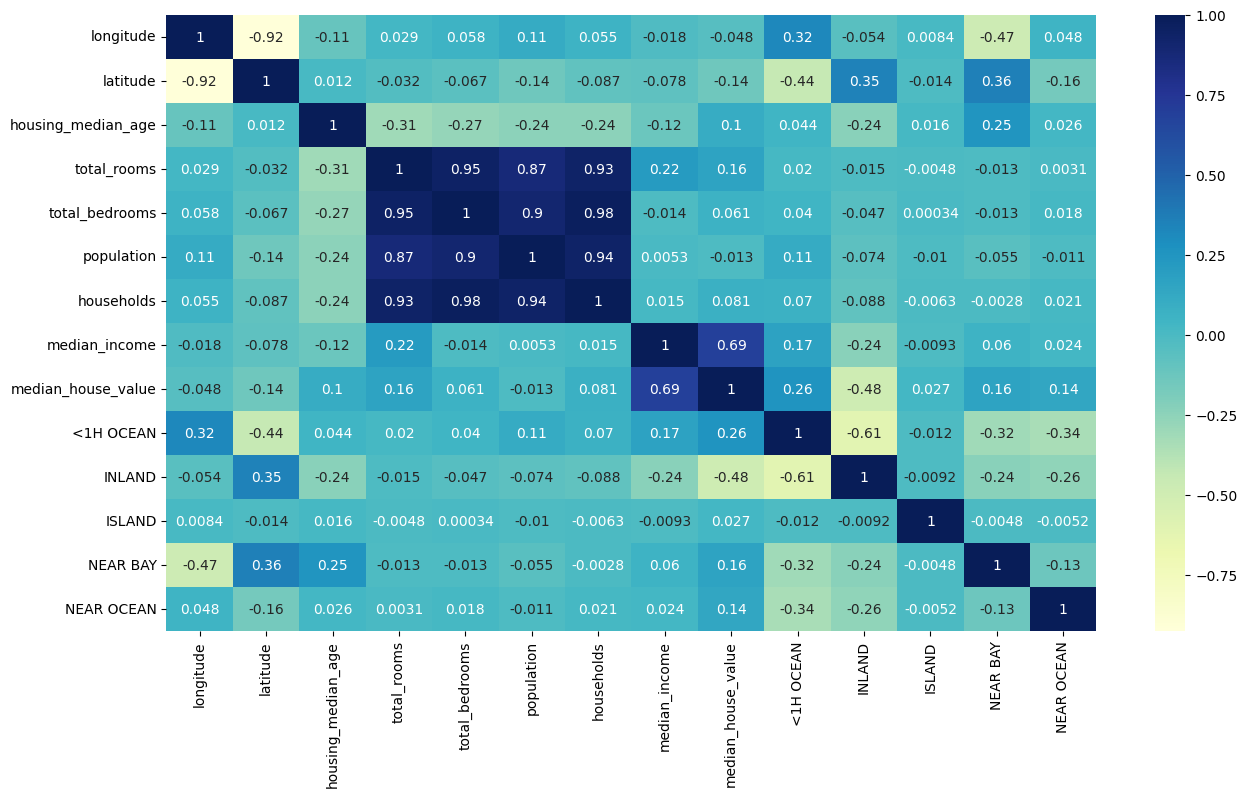

In [30]:
plt.figure(figsize=(15, 8))
sns.heatmap(train_data.corr(numeric_only=True), annot=True, cmap="YlGnBu")

Spread map of higher Value to Costal Category

<Axes: xlabel='latitude', ylabel='longitude'>

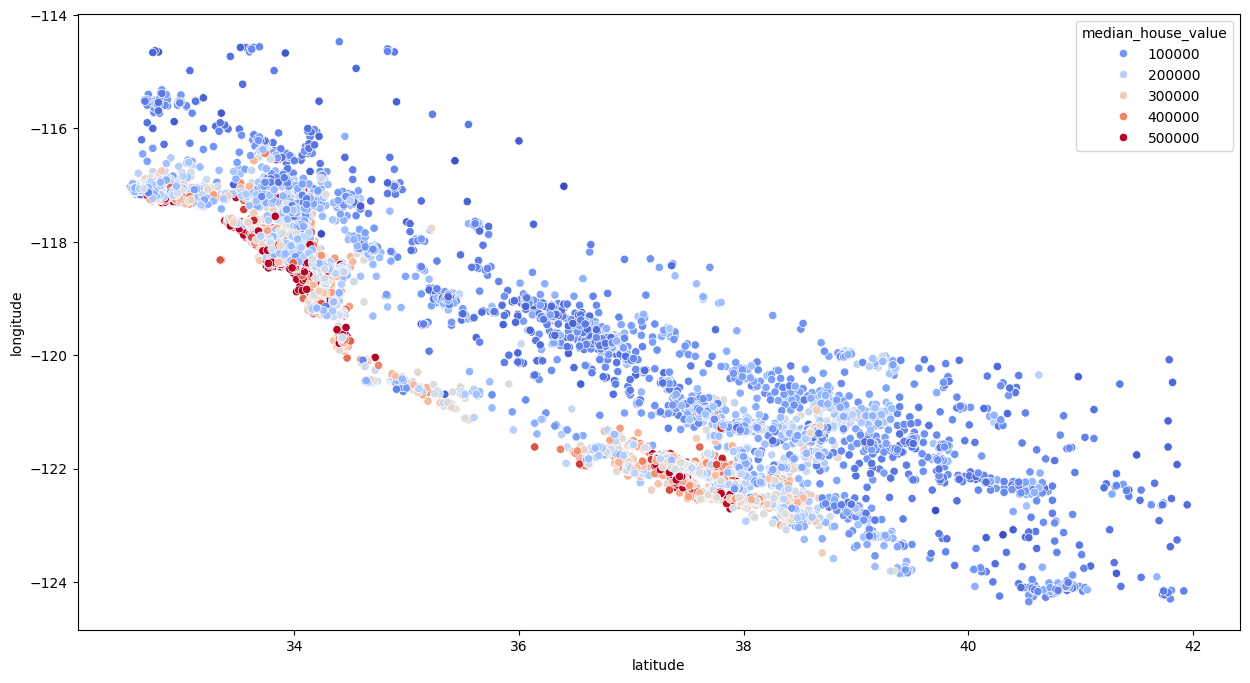

In [31]:
plt.figure(figsize=(15, 8))
sns.scatterplot(x="latitude", y="longitude", data=train_data, hue="median_house_value", palette="coolwarm")